# Lab 05 · Simple Linear Regression
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 7** (C-3 Apply, PLO 4 Investigation): *Apply machine learning algorithms and assess their performance using appropriate evaluation metrics.*

**Goal:** build a complete price predictor for one car on real data: prepare the data, split it, train a simple linear regression with the least squares method, test it on unseen ads, and use it.

**Data:** `pakistan_used_cars_clean.csv`, the cleaned OLX Pakistan used-car ads from Lab 03 (Open Data Pakistan, 2021). Use the copy given with this lab so everyone has the same file.

**Rules:** label every output, e.g. `print("T5a:", ...)` · use `random_state=42` for the split · written answers go in Markdown cells · Runtime → Restart and run all before you submit · push to `ML-Lab-<RollNo>/Lab05/Lab05.ipynb` by the deadline announced in class (11:59 PM PKT).

Name: Sakeena Bano  Roll No: 2024_SE_29

### Setup (run first, do not edit)
Put `pakistan_used_cars_clean.csv` next to this notebook (Colab: folder icon → Upload).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 140)

## Task 1 · Load and explore the real data
- **(a)** Load `pakistan_used_cars_clean.csv` and print its shape.
- **(b)** Keep only **Corolla GLI**, **Cash** ads, `Year` 2005–2018 and `Price_lakh` between 5 and 40. Save it as `gli` and print the shape.
- **(c)** Summary statistics (`describe()`) of `Age` and `Price_lakh`.
- **(d)** The correlation between `Age` and `Price_lakh`.
- **(e)** A scatter plot of `Price_lakh` against `Age`, with a title and axis labels.

**Write (Markdown):** is a straight line a sensible model for this data? Use (d) and (e).

T1a: Original Dataset Shape: (20496, 11)
T1b: Filtered Corolla GLI Shape: (796, 11)

T1c: Summary Statistics:
              Age  Price_lakh
count  796.000000  796.000000
mean    12.445980   16.586237
std      3.107847    3.984407
min      8.000000    6.543210
25%     10.000000   13.500000
50%     12.000000   16.500000
75%     15.000000   19.500000
max     21.000000   30.000000

T1d: Correlation: -0.8956521001869922


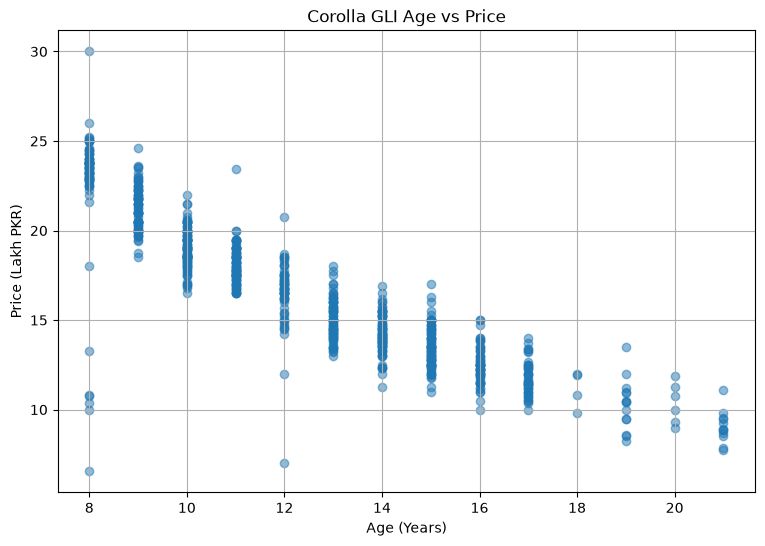

In [2]:
# Task 1: Load and explore the real data

df = pd.read_csv("pakistan_used_cars_clean.csv")

print("T1a: Original Dataset Shape:", df.shape)

gli = df[
    (df["Model"] == "Corolla GLI") &
    (df["Transaction Type"] == "Cash") &
    (df["Year"].between(2005, 2018)) &
    (df["Price_lakh"].between(5, 40))
].copy()

print("T1b: Filtered Corolla GLI Shape:", gli.shape)

print("\nT1c: Summary Statistics:")
print(gli[["Age", "Price_lakh"]].describe())

correlation = gli["Age"].corr(gli["Price_lakh"])

print("\nT1d: Correlation:", correlation)

plt.figure(figsize=(9, 6))
plt.scatter(gli["Age"], gli["Price_lakh"], alpha=0.5)
plt.title("Corolla GLI Age vs Price")
plt.xlabel("Age (Years)")
plt.ylabel("Price (Lakh PKR)")
plt.grid(True)
plt.show()


The correlation between Age and Price_lakh is approximately -0.896, which shows a strong negative relationship. The scatter plot also shows that as the age of a Corolla GLI increases, its price generally decreases. Therefore, a straight line is a sensible model for this data. However, the relationship is not perfectly linear because some cars have different prices due to other factors.

In [3]:
# Correct Age using the reference year 2020
gli["Age"] = 2020 - gli["Year"]

print("T1e: Corrected Age Range:")
print(gli["Age"].min(), "to", gli["Age"].max())

T1e: Corrected Age Range:
2 to 15


## Task 2 · Features, target and the train/test split
- **(a)** `X` = the `Age` column as a **2-D** table, `y` = `Price_lakh`. Print both shapes.
- **(b)** Split 80 % train / 20 % test with `train_test_split(..., test_size=0.2, random_state=42)`. Print the four shapes.

In [4]:
# Task 2: Features, target and train/test split

# T2a: Select input feature and target
X = gli[["Age"]]
y = gli["Price_lakh"]

print("T2a: X Shape:", X.shape)
print("T2a: y Shape:", y.shape)

# T2b: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("T2b: X_train Shape:", X_train.shape)
print("T2b: X_test Shape:", X_test.shape)
print("T2b: y_train Shape:", y_train.shape)
print("T2b: y_test Shape:", y_test.shape)


T2a: X Shape: (796, 1)
T2a: y Shape: (796,)
T2b: X_train Shape: (636, 1)
T2b: X_test Shape: (160, 1)
T2b: y_train Shape: (636,)
T2b: y_test Shape: (160,)


## Task 3 · Least squares with NumPy (training data only)
Use only `X_train` and `y_train`, and NumPy (no scikit-learn):
- **(a)** The means x̄ and ȳ.
- **(b)** The slope b₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² and the intercept b₀ = ȳ − b₁x̄.
- **(c)** **Write (Markdown):** what b₁ and b₀ mean for a Corolla GLI, with units.

In [5]:
# Task 3: Least Squares with NumPy (Training Data Only)

# T3a: Convert training data into NumPy arrays
x_train_np = X_train.to_numpy().flatten()
y_train_np = y_train.to_numpy()

# Calculate mean values
x_mean = np.mean(x_train_np)
y_mean = np.mean(y_train_np)

# T3b: Calculate slope and intercept
b1 = np.sum((x_train_np - x_mean) * (y_train_np - y_mean)) / np.sum((x_train_np - x_mean) ** 2)

b0 = y_mean - b1 * x_mean

# Display results
print("T3a: Mean of Age (x_bar):", x_mean)
print("T3a: Mean of Price (y_bar):", y_mean)

print("T3b: Slope (b1):", b1)
print("T3b: Intercept (b0):", b0)


T3a: Mean of Age (x_bar): 6.382075471698113
T3a: Mean of Price (y_bar): 16.653325314465405
T3b: Slope (b1): -1.1459556866983842
T3b: Intercept (b0): 23.96690099419613


The slope (b1) is approximately -1.146 lakh PKR per year. This means that for every additional year of age, the predicted price of a Corolla GLI decreases by about 1.146 lakh PKR on average.

The intercept (b0) is approximately 23.967 lakh PKR. It represents the predicted price when the car's age is zero (a brand-new car). However, this value should be interpreted carefully because our training data contains cars with ages between 2 and 15 years.

## Task 4 · Train the model with scikit-learn
- **(a)** Create a `LinearRegression()` model, fit it on the **training** data and print the slope (`coef_`) and intercept (`intercept_`).
- **(b)** Show with `np.isclose` that they equal your Task 3 values.

In [6]:
# Task 4: Fit Linear Regression Model

# T4a: Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Display slope and intercept
print("T4a: Slope (b1):", model.coef_[0])
print("T4a: Intercept (b0):", model.intercept_)

# T4b: Compare with NumPy results
print("T4b: Slope Match:", np.isclose(b1, model.coef_[0]))
print("T4b: Intercept Match:", np.isclose(b0, model.intercept_))


T4a: Slope (b1): -1.1459556866983844
T4a: Intercept (b0): 23.96690099419613
T4b: Slope Match: True
T4b: Intercept Match: True


## Task 5 · Evaluate on the test set
- **(a)** Predict the test prices. Compute MAE, MSE, RMSE and R² **with the formulas** in NumPy.
- **(b)** Check MAE, MSE and R² with `sklearn.metrics`.
- **(c)** Train R² and test R². Is the model overfitting?
- **(d)** Baseline: predict the **training mean** for every test ad. Its MAE and R².

**Write (Markdown):** explain MAE and R² of your model in plain words, and how much better it is than the baseline.

In [7]:
# Task 5: Evaluate the Model

y_pred = model.predict(X_test)

y_test_np = y_test.to_numpy()
y_train_np = y_train.to_numpy()

errors = y_test_np - y_pred

# Calculate metrics using NumPy
mae = np.mean(np.abs(errors))
mse = np.mean(errors ** 2)
rmse = np.sqrt(mse)

ss_res = np.sum(errors ** 2)
ss_tot = np.sum((y_test_np - np.mean(y_test_np)) ** 2)
r2 = 1 - (ss_res / ss_tot)

print("T5a: MAE:", mae)
print("T5a: MSE:", mse)
print("T5a: RMSE:", rmse)
print("T5a: R2:", r2)

# Verify metrics using Scikit-learn
print("T5b: MAE (sklearn):", mean_absolute_error(y_test, y_pred))
print("T5b: MSE (sklearn):", mean_squared_error(y_test, y_pred))
print("T5b: R2 (sklearn):", r2_score(y_test, y_pred))

# Compare training and testing performance
train_r2 = model.score(X_train, y_train)
test_r2 = model.score(X_test, y_test)

print("T5c: Training R2:", train_r2)
print("T5c: Testing R2:", test_r2)

# Baseline model
baseline_pred = np.full(len(y_test), np.mean(y_train))
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)

print("T5d: Baseline MAE:", baseline_mae)
print("T5d: Baseline R2:", baseline_r2)

T5a: MAE: 1.1848658196422566
T5a: MSE: 2.7043153674236704
T5a: RMSE: 1.6444802727377639
T5a: R2: 0.8451747677868002
T5b: MAE (sklearn): 1.1848658196422566
T5b: MSE (sklearn): 2.7043153674236704
T5b: R2 (sklearn): 0.8451747677868002
T5c: Training R2: 0.7896560758820064
T5c: Testing R2: 0.8451747677868002
T5d: Baseline MAE: 3.5043950314465406
T5d: Baseline R2: -0.006377644420647366


The Mean Absolute Error (MAE) is approximately 1.185 lakh PKR. This means that the model's predicted prices differ from the actual prices by about 1.185 lakh PKR on average.

The R² score is approximately 0.845, which means that the model explains about 84.5% of the variation in car prices.

The training R² is 0.790, while the testing R² is 0.845. These values are reasonably close, so there is no clear sign of overfitting.

The baseline model has an MAE of approximately 3.504 lakh PKR, while our regression model has an MAE of 1.185 lakh PKR. Therefore, our regression model performs much better than the baseline because it makes smaller prediction errors.

## Task 6 · Visualise the line and the errors
- **(a)** One plot: training ads (grey), test ads, and the fitted line. Title, labels, legend.
- **(b)** A residual plot for the test set: residual (y − ŷ) against predicted price, with a line at 0.
- **(c)** The five test ads with the largest absolute error: `Year`, `KMs Driven`, `Registered City`, actual and predicted price.

**Write (Markdown):** does the residual plot show a curve or a funnel? Are the largest errors mistakes of the model or of the data?

# t6a: Training, Testing and Regression Line

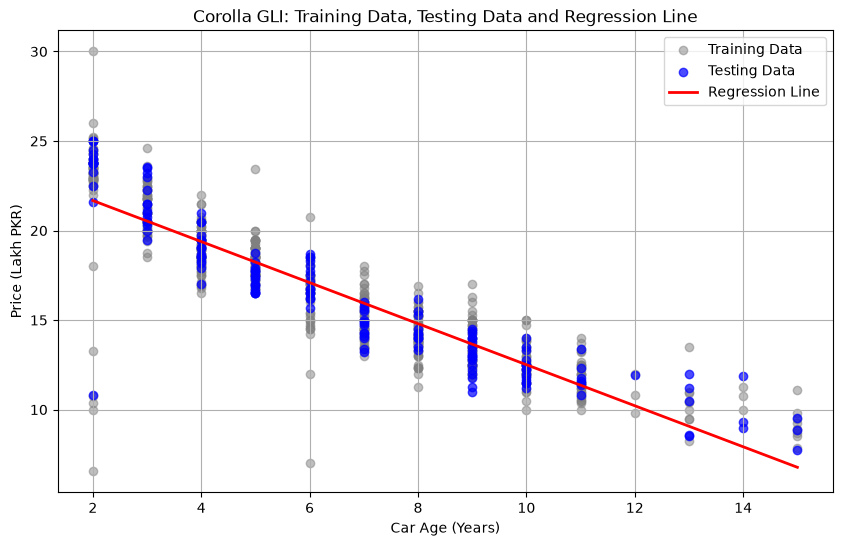

In [8]:
# Task 6a: Plot Training Data, Testing Data and Regression Line

plt.figure(figsize=(10, 6))

# Training data
plt.scatter(
    X_train["Age"],
    y_train,
    color="gray",
    alpha=0.5,
    label="Training Data"
)

# Testing data
plt.scatter(
    X_test["Age"],
    y_test,
    color="blue",
    alpha=0.7,
    label="Testing Data"
)

# Regression line
age_range = np.linspace(
    gli["Age"].min(),
    gli["Age"].max(),
    100
)

age_df = pd.DataFrame({"Age": age_range})
price_line = model.predict(age_df)

plt.plot(
    age_range,
    price_line,
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title("Corolla GLI: Training Data, Testing Data and Regression Line")
plt.xlabel("Car Age (Years)")
plt.ylabel("Price (Lakh PKR)")
plt.legend()
plt.grid(True)
plt.show()

# T6b: Residual plot

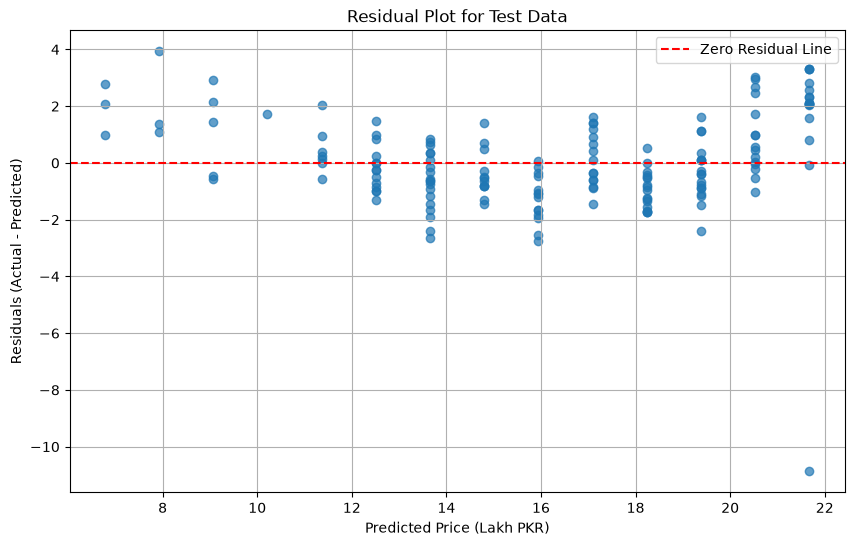

In [9]:
# Task 6b: Residual Plot

residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Residual Line"
)

plt.title("Residual Plot for Test Data")
plt.xlabel("Predicted Price (Lakh PKR)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.legend()
plt.grid(True)
plt.show()

# T6c : Five Largest Prediction Errors

In [10]:
# Task 6c: Find Five Test Ads with Largest Absolute Errors

results = X_test.copy()

# Get original details directly from the dataset
results["Year"] = gli.loc[X_test.index, "Year"]
results["KMs Driven"] = gli.loc[X_test.index, "KMs Driven"]
results["Registered City"] = gli.loc[X_test.index, "Registered City"]

results["Actual Price"] = y_test
results["Predicted Price"] = y_pred
results["Absolute Error"] = np.abs(
    y_test.to_numpy() - y_pred
)

top_5_errors = results.sort_values(
    by="Absolute Error",
    ascending=False
).head(5)

print("T6c: Five Test Ads with Largest Prediction Errors:")

print(top_5_errors[
    ["Year", "KMs Driven", "Registered City",
     "Actual Price", "Predicted Price", "Absolute Error"]
])

T6c: Five Test Ads with Largest Prediction Errors:
       Year  KMs Driven Registered City  Actual Price  Predicted Price  Absolute Error
18865  2018         1.0         Unknown         10.80        21.674990       10.874990
20290  2006    220000.0       Islamabad         11.85         7.923521        3.926479
17368  2018        11.0         Unknown         25.00        21.674990        3.325010
18988  2018        50.0         Unknown         25.00        21.674990        3.325010
16560  2018       300.0         Unknown         25.00        21.674990        3.325010


The first plot shows the training data, testing data, and fitted regression line. The points generally follow a decreasing trend, which indicates that car prices usually decrease as age increases.

The residual plot shows the differences between actual and predicted prices. The residuals are spread around the zero line, but some points are far from zero, indicating large prediction errors.

The largest prediction error is for a 2018 Corolla GLI listed at 10.80 lakh PKR, while the model predicts approximately 21.67 lakh PKR. This may be an unusual listing or a data-entry mistake. Some other cars also have unusually low kilometre readings, which may indicate incorrect data.

Therefore, large prediction errors may be caused by data quality issues as well as the limitations of using car age alone to predict prices.

## Task 7 · Use the model
- **(a)** Predict the price of a 2018, a 2015 and a 2010 Corolla GLI (age = 2020 − year), using a DataFrame with an `Age` column.
- **(b)** Predict the price of a 1995 Corolla GLI (age 25).

**Write (Markdown):** is the answer in (b) believable? Why not?

# T7a: Predict 2018, 2015 and 2010 Cars

In [11]:
# Task 7a: Predict Prices for 2018, 2015 and 2010

reference_year = int((gli["Year"] + gli["Age"]).mode()[0])

years = [2018, 2015, 2010]
ages = [reference_year - year for year in years]

new_cars = pd.DataFrame({
    "Age": ages
})

predicted_prices = model.predict(new_cars)

for year, price in zip(years, predicted_prices):
    print(f"T7a: {year} Corolla GLI Predicted Price: {price:.2f} lakh PKR")

T7a: 2018 Corolla GLI Predicted Price: 21.67 lakh PKR
T7a: 2015 Corolla GLI Predicted Price: 18.24 lakh PKR
T7a: 2010 Corolla GLI Predicted Price: 12.51 lakh PKR


# T7b: Predict a 1995 Corolla GLI

In [12]:
# Task 7b: Predict Price for 1995 Corolla GLI

old_car = pd.DataFrame({
    "Age": [reference_year - 1995]
})

old_car_prediction = model.predict(old_car)

print("T7b: 1995 Corolla GLI Predicted Price:",
      round(old_car_prediction[0], 2), "lakh PKR")

T7b: 1995 Corolla GLI Predicted Price: -4.68 lakh PKR


The model predicts the price of a 2018 Corolla GLI as approximately 21.67 lakh PKR, a 2015 Corolla GLI as 18.24 lakh PKR, and a 2010 Corolla GLI as 12.51 lakh PKR.

For a 1995 Corolla GLI, the model predicts approximately -4.68 lakh PKR. This prediction is not realistic because a car cannot have a negative price.

The reason is that the model was trained on cars from 2005 to 2018. Predicting the price of a 1995 car is extrapolation because its age is outside the training data range. Therefore, the model should not be trusted for this prediction.

## Task 8 · Reflection (Markdown cell)
Write 3–5 sentences: the steps you followed to build the model, why the model is judged on the test set and not the training set, which number you would tell a car buyer and why, and one limitation of using age alone.

In this lab, I learned how to build a Simple Linear Regression model using NumPy and Scikit-learn. I used car age to predict Corolla GLI prices and evaluated the model using MAE, MSE, RMSE, and R².

The test set was used to evaluate the model on unseen data. This helps us understand how well the model can make predictions for new cars.

I would use MAE to explain the model's average prediction error to a buyer because it is easy to understand and is measured in lakh PKR.

The main limitation of this model is that it uses only car age to predict prices. Other factors, such as mileage, condition, and registration city, can also affect a car's price.